<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_1_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!nvidia-smi

Fri Nov  6 15:21:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 1. OpenCV ve Derleme Araçlarının Kurulumu
Colab üzerinde C++ ile OpenCV kullanabilmek için gerekli paketleri kuruyoruz.

In [17]:
!apt-get update && apt-get install -y libopencv-dev g++

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information...

### 2. C++ Kodunun Yazılması (`odev1.cpp`)
Aşağıdaki C++ kodu belirtilen dizindeki resimleri tarar, okur, OpenCV'nin `resize` fonksiyonunu ve enterpolasyon (`INTER_LINEAR`) metodunu kullanarak 1024x768 boyutuna getirir ve kaydeder. Denemek için geçici bir `test_images` klasörü oluşturup içine örnek görseller ekleyebilirsiniz.

In [21]:
%%writefile odev1.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <vector>
#include <string>

using namespace std;
using namespace cv;

int main() {
    cout << "C++ ve OpenCV ile Görüntü Boyutlandırma Başlıyor!" << endl;

    // Test amaçlı klasör oluşturulduğunu varsayıyoruz
    string input_dir = "test_images/";
    string output_dir = "output_images/";

    // Klasör oluşturma komutları
    string make_output_dir = "mkdir -p " + output_dir;
    system(make_output_dir.c_str());

    // Dizindeki dosyaları oku
    vector<String> fn;
    glob(input_dir + "*.jpg", fn, false); // .jpg dosyalarını bul

    if (fn.empty()) {
        cout << "Hata: 'test_images' klasöründe .jpg dosyası bulunamadı!" << endl;
        cout << "Lütfen test etmek için 'test_images' adında bir klasör oluşturup içine örnek görseller yükleyin." << endl;
        return -1;
    }

    size_t count = fn.size();
    cout << "Toplam bulunan görsel sayısı: " << count << endl;

    for (size_t i = 0; i < count; i++) {
        Mat src = imread(fn[i]);
        if (src.empty()) {
            cout << "Görüntü okunamadı: " << fn[i] << endl;
            continue;
        }

        Mat dst;
        // 1024x768 hedef çözünürlüğü
        Size target_size(1024, 768);

        // INTER_LINEAR enterpolasyonu ile yeniden boyutlandırma
        resize(src, dst, target_size, 0, 0, INTER_LINEAR);

        // Dosya adını ayıkla (Linux uyumlu olarak tek tırnakla '/' karakteri aratılıyor)
        size_t last_slash_idx = fn[i].find_last_of('/');
        string filename = (last_slash_idx == string::npos) ? fn[i] : fn[i].substr(last_slash_idx + 1);

        // Yeni görseli kaydet
        string out_path = output_dir + "resized_" + filename;
        imwrite(out_path, dst);

        cout << fn[i] << " -> " << out_path << " [Başarılı]" << endl;
    }

    cout << "İşlem tamamlandı! Yeniden boyutlandırılan resimler 'output_images/' klasörüne kaydedildi." << endl;
    return 0;
}

Overwriting odev1.cpp


### 3. Örnek Test Klasörü Oluşturma ve Test Resmi İndirme
Kodun çalışmasını gözlemleyebilmek için hızlıca örnek bir klasör ve görsel oluşturuyoruz.

In [19]:
!mkdir -p test_images
# Örnek bir manzara fotoğrafı indiriyoruz
!wget -O test_images/sample1.jpg https://picsum.photos/1600/1200
!wget -O test_images/sample2.jpg https://picsum.photos/1920/1080

--2026-11-06 15:21:34--  https://picsum.photos/1600/1200
Resolving picsum.photos (picsum.photos)... 104.26.4.30, 104.26.5.30, 172.67.74.163, ...
Connecting to picsum.photos (picsum.photos)|104.26.4.30|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://fastly.picsum.photos/id/521/1600/1200.jpg?hmac=Gkr1hO6yk1M-PLp-dzoAlvbePK3SJZphfCSNW2TLjhU [following]
--2026-11-06 15:21:34--  https://fastly.picsum.photos/id/521/1600/1200.jpg?hmac=Gkr1hO6yk1M-PLp-dzoAlvbePK3SJZphfCSNW2TLjhU
Resolving fastly.picsum.photos (fastly.picsum.photos)... 151.101.1.91, 151.101.65.91, 151.101.129.91, ...
Connecting to fastly.picsum.photos (fastly.picsum.photos)|151.101.1.91|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 203529 (199K) [image/jpeg]
Saving to: ‘test_images/sample1.jpg’

test_images/sample1 100%[===================>] 198.76K  --.-KB/s    in 0.02s   

2026-11-06 15:21:34 (11.8 MB/s) - ‘test_images/sample1.jpg’ saved [203529/203529]

--202

### 4. Kodun Derlenmesi ve Çalıştırılması
`g++` derleyicisi kullanarak yazdığımız programı OpenCV kütüphanelerini bağlayarak (`pkg-config`) derliyoruz ve ardından çalıştırıyoruz.

In [20]:
!g++ odev1.cpp -o odev1 `pkg-config --cflags --libs opencv4` && ./odev1

odev1.cpp:48:52: warning: missing terminating " character
   48 |         size_t last_slash_idx = fn[i].find_last_of("\/\");
      |                                                    ^
odev1.cpp:48:52: error: missing terminating " character
   48 |         size_t last_slash_idx = fn[i].find_last_of("\/\");
      |                                                    ^~~~~~~
odev1.cpp: In function ‘int main()’:
odev1.cpp:49:16: error: expected primary-expression before ‘filename’
   49 |         string filename = (last_slash_idx == string::npos) ? fn[i] : fn[i].substr(last_slash_idx + 1);
      |                ^~~~~~~~
odev1.cpp:52:53: error: ‘filename’ was not declared in this scope; did you mean ‘rename’?
   52 |         string out_path = output_dir + "resized_" + filename;
      |                                                     ^~~~~~~~
      |                                                     rename


In [22]:
!g++ odev1.cpp -o odev1 `pkg-config --cflags --libs opencv4` && ./odev1

C++ ve OpenCV ile Görüntü Boyutlandırma Başlıyor!
Toplam bulunan görsel sayısı: 2
test_images/sample1.jpg -> output_images/resized_sample1.jpg [Başarılı]
test_images/sample2.jpg -> output_images/resized_sample2.jpg [Başarılı]
İşlem tamamlandı! Yeniden boyutlandırılan resimler 'output_images/' klasörüne kaydedildi.


In [23]:
# Oluşturulan çıktı dosyalarını doğrulayalım
!ls -la output_images/

total 596
drwxr-xr-x 2 root root   4096 Nov  6 15:23 .
drwxr-xr-x 1 root root   4096 Nov  6 15:23 ..
-rw-r--r-- 1 root root 244166 Nov  6 15:23 resized_sample1.jpg
-rw-r--r-- 1 root root 353793 Nov  6 15:23 resized_sample2.jpg


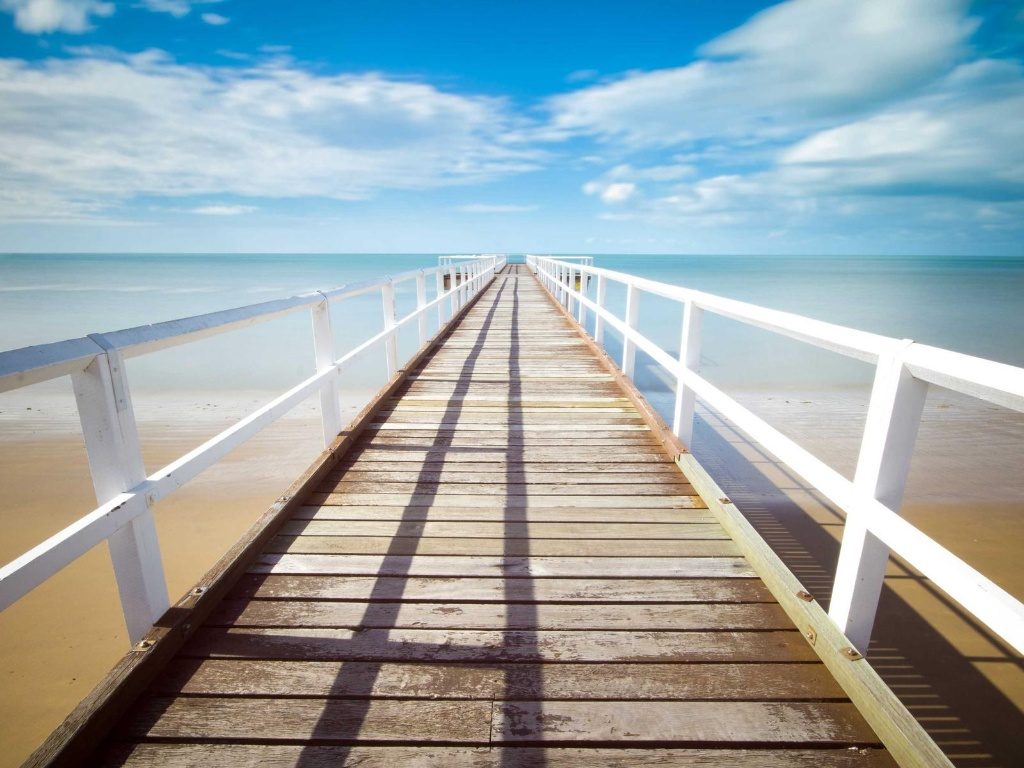

In [24]:
from IPython.display import Image, display

# Yeniden boyutlandırılmış ilk görseli notebook içerisinde görüntülüyoruz
image_path = 'output_images/resized_sample1.jpg'
display(Image(filename=image_path))

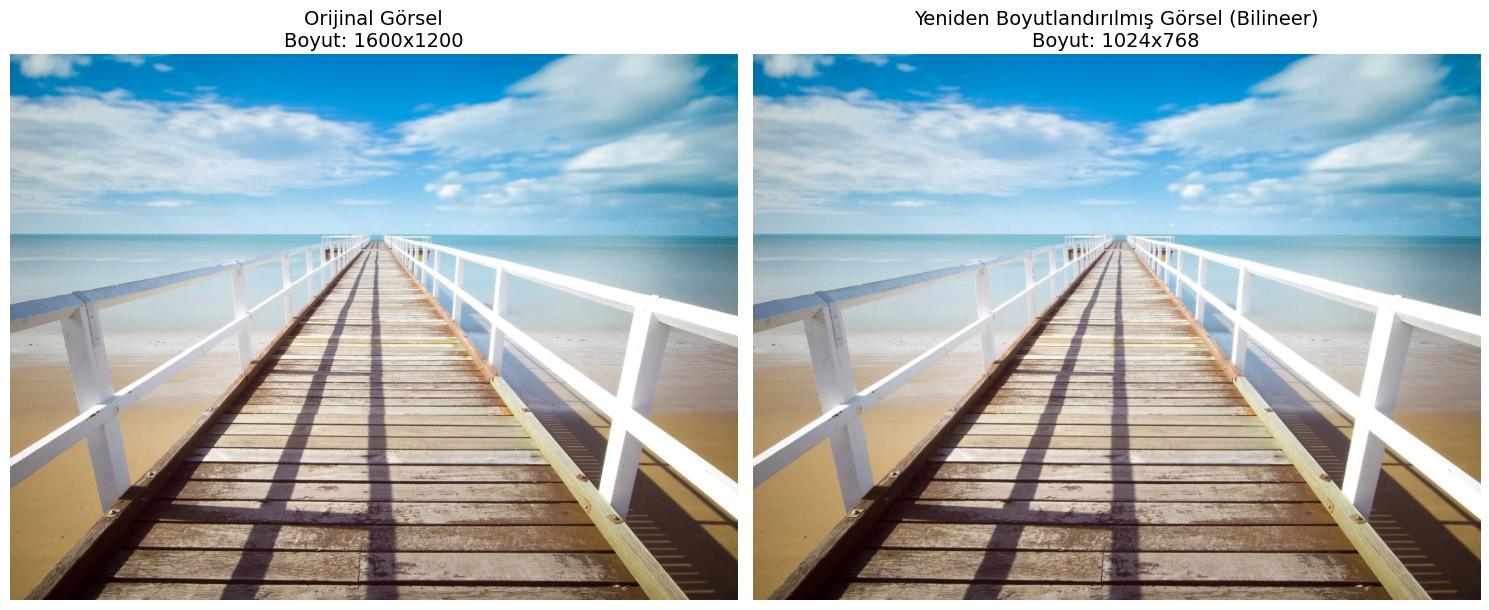

In [25]:
import cv2
import matplotlib.pyplot as plt

# Orijinal ve yeniden boyutlandırılmış görsellerin yollarını tanımlayalım
original_path = 'test_images/sample1.jpg'
resized_path = 'output_images/resized_sample1.jpg'

# Görselleri OpenCV ile okuyalım (OpenCV varsayılan olarak BGR okur, matplotlib için RGB'ye çeviriyoruz)
img_original = cv2.cvtColor(cv2.imread(original_path), cv2.COLOR_BGR2RGB)
img_resized = cv2.cvtColor(cv2.imread(resized_path), cv2.COLOR_BGR2RGB)

# Görsel boyutlarını alalım
h_orig, w_orig, _ = img_original.shape
h_res, w_res, _ = img_resized.shape

# Yan yana çizdirelim
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Orijinal Görsel
axes[0].imshow(img_original)
axes[0].set_title(f"Orijinal Görsel\nBoyut: {w_orig}x{h_orig}", fontsize=14)
axes[0].axis('off')

# Yeniden Boyutlandırılmış Görsel
axes[1].imshow(img_resized)
axes[1].set_title(f"Yeniden Boyutlandırılmış Görsel (Bilineer)\nBoyut: {w_res}x{h_res}", fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [26]:
%%writefile odev1_cubic.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <vector>
#include <string>

using namespace std;
using namespace cv;

int main() {
    cout << "C++ ve OpenCV ile Bicubic Boyutlandırma Başlıyor!" << endl;

    string input_dir = "test_images/";
    string output_dir = "output_images_cubic/";

    string make_output_dir = "mkdir -p " + output_dir;
    system(make_output_dir.c_str());

    vector<String> fn;
    glob(input_dir + "*.jpg", fn, false);

    if (fn.empty()) {
        cout << "Hata: 'test_images' klasöründe görsel bulunamadı!" << endl;
        return -1;
    }

    size_t count = fn.size();
    cout << "Toplam bulunan görsel sayısı: " << count << endl;

    for (size_t i = 0; i < count; i++) {
        Mat src = imread(fn[i]);
        if (src.empty()) {
            continue;
        }

        Mat dst;
        Size target_size(1024, 768);

        // INTER_CUBIC enterpolasyonu kullanılıyor
        resize(src, dst, target_size, 0, 0, INTER_CUBIC);

        size_t last_slash_idx = fn[i].find_last_of('/');
        string filename = (last_slash_idx == string::npos) ? fn[i] : fn[i].substr(last_slash_idx + 1);

        string out_path = output_dir + "cubic_" + filename;
        imwrite(out_path, dst);

        cout << fn[i] << " -> " << out_path << " [Başarılı]" << endl;
    }

    cout << "İşlem tamamlandı!" << endl;
    return 0;
}

Writing odev1_cubic.cpp


In [27]:
!g++ odev1_cubic.cpp -o odev1_cubic `pkg-config --cflags --libs opencv4` && ./odev1_cubic

C++ ve OpenCV ile Bicubic Boyutlandırma Başlıyor!
Toplam bulunan görsel sayısı: 2
test_images/sample1.jpg -> output_images_cubic/cubic_sample1.jpg [Başarılı]
test_images/sample2.jpg -> output_images_cubic/cubic_sample2.jpg [Başarılı]
İşlem tamamlandı!


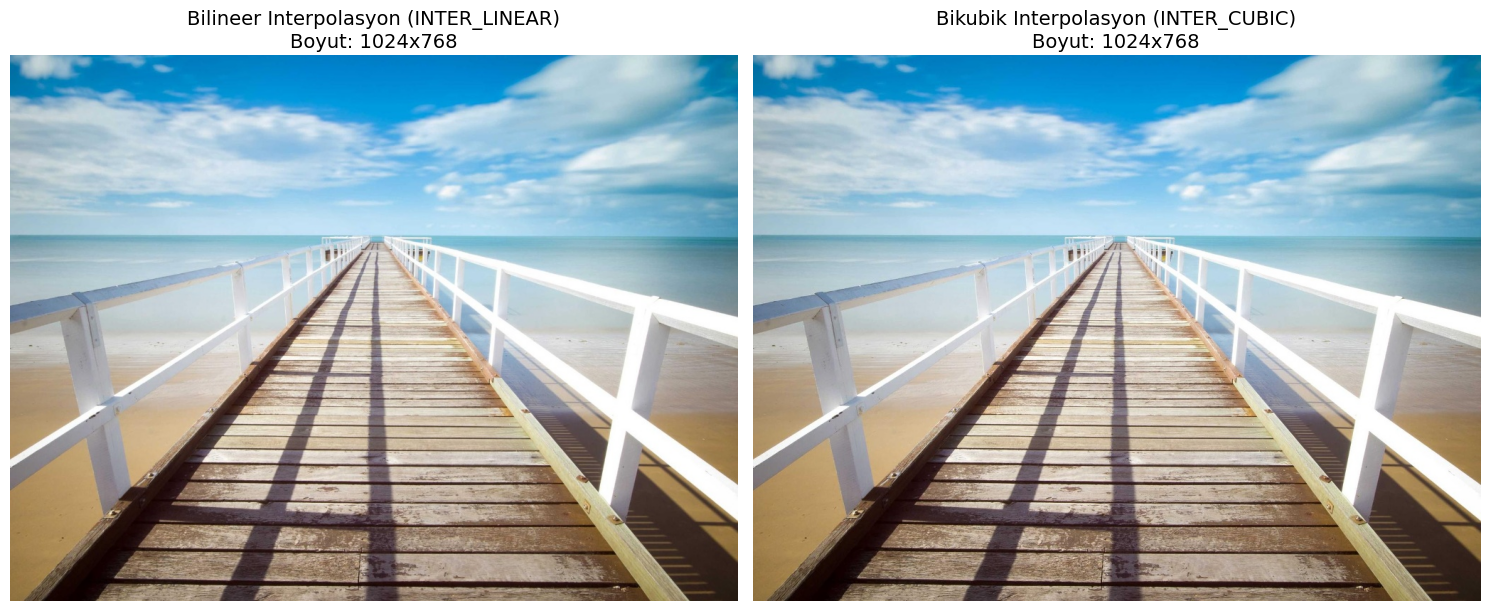

In [28]:
import cv2
import matplotlib.pyplot as plt

# Bilineer ve Bikubik görsel çıktılarının yolları
linear_path = 'output_images/resized_sample1.jpg'
cubic_path = 'output_images_cubic/cubic_sample1.jpg'

img_linear = cv2.cvtColor(cv2.imread(linear_path), cv2.COLOR_BGR2RGB)
img_cubic = cv2.cvtColor(cv2.imread(cubic_path), cv2.COLOR_BGR2RGB)

# İki farklı yöntemi yan yana kıyaslayalım
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Bilineer Çıktı
axes[0].imshow(img_linear)
axes[0].set_title("Bilineer Interpolasyon (INTER_LINEAR)\nBoyut: 1024x768", fontsize=14)
axes[0].axis('off')

# Bikubik Çıktı
axes[1].imshow(img_cubic)
axes[1].set_title("Bikubik Interpolasyon (INTER_CUBIC)\nBoyut: 1024x768", fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

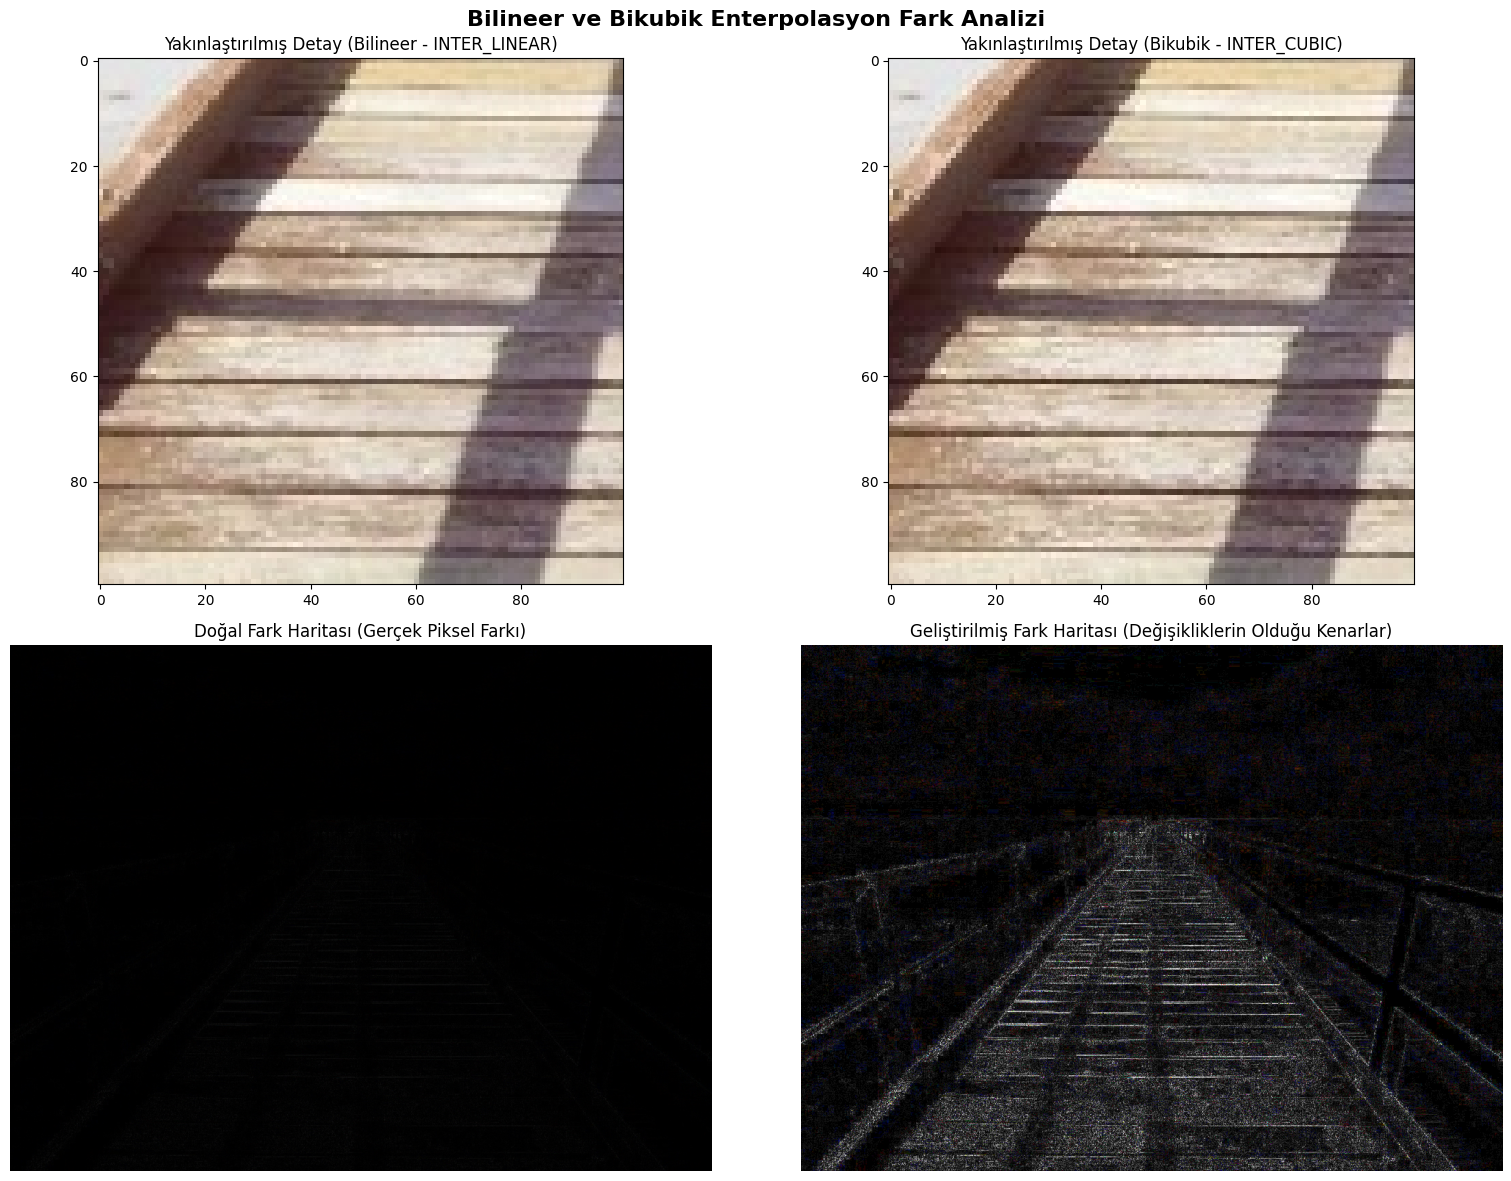

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Görselleri tekrar yükleyelim
img_linear = cv2.cvtColor(cv2.imread('output_images/resized_sample1.jpg'), cv2.COLOR_BGR2RGB)
img_cubic = cv2.cvtColor(cv2.imread('output_images_cubic/cubic_sample1.jpg'), cv2.COLOR_BGR2RGB)

# 1. Fark Görseli Oluşturma (Absolute Difference)
# İki görsel arasındaki piksel farklarını hesaplıyoruz
diff_img = cv2.absdiff(img_linear, img_cubic)

# Farkı gözle rahat görebilmek için kontrastını yapay olarak artırıyoruz (farkları 15 ile çarpıyoruz)
diff_enhanced = np.clip(diff_img * 15, 0, 255).astype(np.uint8)

# 2. Yakınlaştırılmış Bölge (Zoom) Seçimi
# Resmin merkezindeki iskele parmaklıklarının bir detayına odaklanalım (örneğin y ekseni 400-500, x ekseni 350-450)
y1, y2, x1, x2 = 400, 500, 350, 450
zoom_linear = img_linear[y1:y2, x1:x2]
zoom_cubic = img_cubic[y1:y2, x1:x2]

# Görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Sol Üst: Yakınlaştırılmış Bilineer
axes[0, 0].imshow(zoom_linear)
axes[0, 0].set_title("Yakınlaştırılmış Detay (Bilineer - INTER_LINEAR)", fontsize=12)
axes[0, 0].axis('on') # Piksel koordinatlarını görebilmek için açık bıraktık

# Sağ Üst: Yakınlaştırılmış Bikubik
axes[0, 1].imshow(zoom_cubic)
axes[0, 1].set_title("Yakınlaştırılmış Detay (Bikubik - INTER_CUBIC)", fontsize=12)
axes[0, 1].axis('on')

# Sol Alt: Orijinal Fark Haritası
axes[1, 0].imshow(diff_img)
axes[1, 0].set_title("Doğal Fark Haritası (Gerçek Piksel Farkı)", fontsize=12)
axes[1, 0].axis('off')

# Sağ Alt: Belirginleştirilmiş Fark Haritası
axes[1, 1].imshow(diff_enhanced)
axes[1, 1].set_title("Geliştirilmiş Fark Haritası (Değişikliklerin Olduğu Kenarlar)", fontsize=12)
axes[1, 1].axis('off')

plt.suptitle("Bilineer ve Bikubik Enterpolasyon Fark Analizi", fontsize=16, weight='bold')
plt.tight_layout()
plt.show()